# 1.0 Carga, exploración (EDA) y preprocesamiento – Consumidores hipervulnerables

**Proyecto de Aprendizaje Automático – Centro Politécnico Superior Malvinas Argentinas**

**Objetivo del notebook:** cargar el dataset, explorarlo (instancias, columnas, tipos de datos, calidad,
distribuciones, asociaciones) y dejarlo preparado para entrenar modelos: normalización de formato, agrupación
de rubros, selección de variables, codificación de variables categóricas, escalado y partición
entrenamiento/prueba. **En este notebook no se entrena ningún modelo** (el modelado va en un notebook aparte).

La descripción del dataset y su origen están en `docs/01_descripcion_dataset.md`; las decisiones y su
justificación, en `docs/02_decisiones_metodologicas.md`.

**Fuente:** Datos Argentina, Ministerio de Desarrollo Productivo. Programa Consumidores Hipervulnerables.
El enlace y la fecha de descarga están en el `README.md` del repositorio.

> Las secciones 1 a 5 y 8 son exploración descriptiva del conjunto completo; las decisiones de diseño (clases,
> variables) se toman con el conjunto de entrenamiento o por disponibilidad de los datos.
>
> Todo el análisis se refiere únicamente a los **reclamos registrados** en el dataset y a su período. No
> permite afirmar nada sobre las personas que no reclamaron ni sobre cuántas personas de cada grupo
> consumen cada servicio. Las explicaciones posibles de lo que se observa se presentan como **hipótesis**,
> no como conclusiones.


In [1]:
# Importaciones: pandas/numpy para manejar datos, matplotlib para los gráficos y scikit-learn solo para
# el preprocesamiento (partición, codificación y escalado). No se importa ningún modelo.
import sys
sys.path.insert(0, "..")  # permite importar el módulo del repositorio desde la carpeta notebooks

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib  # para guardar y volver a cargar el preprocesador ajustado

# Funciones propias (carga, limpieza, agrupación de rubros, V de Cramér) definidas en
# consumidores_hipervulnerables/dataset.py para que el código quede reutilizable.
from consumidores_hipervulnerables.dataset import (
    INTERIM, MODELOS, PROCESSED, aplicar_clases, cargar_crudo, clave_fila, cramer_v, definir_clases,
    normalizar, particion_entrenamiento_prueba,
)
from consumidores_hipervulnerables.features import ESCENARIOS, construir_preprocesador

FIG = Path("../reports/figures")          # carpeta donde se guardan los gráficos
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 150)        # evita que las tablas anchas se corten
pd.set_option("display.max_colwidth", 70)
SEMILLA = 42  # semilla fija: la partición entrenamiento/prueba será siempre la misma


## 1. Carga y estructura del archivo original

In [2]:
# Se lee el CSV tal como viene (latin-1) para conocer su estructura antes de tocar nada.
raw = cargar_crudo()
print("Instancias (filas):", raw.shape[0])
print("Características (columnas):", raw.shape[1])
print("Columnas tal como vienen en el archivo:", list(raw.columns))
raw.head(3)  # primeras filas para ver el contenido real

Instancias (filas): 6457
Características (columnas): 8
Columnas tal como vienen en el archivo: ['rubro', 'motivo', 'vulnerabilidad', 'mes_año_tratamiento', 'edad', 'genero', 'provincia_consumidor', 'provincia_id;;;']


,rubro,motivo,vulnerabilidad,mes_año_tratamiento,edad,genero,provincia_consumidor,provincia_id;;;
0,Servicios de comunicaciones,Cumplimiento parcial o defectuoso de la prestación del servicio,Adulto/a mayor,ene-21,51,Femenino,Buenos Aires,6;;;
1,Servicios de comunicaciones,Facturación excesiva/ facturación cargos no convenidos,Socio-económica,feb-21,64,Masculino,Ciudad Autónoma de Buenos Aires,2;;;
2,Servicios de comunicaciones,Cumplimiento parcial o defectuoso de la prestación del servicio,Adulto/a mayor,feb-21,46,Femenino,Buenos Aires,6;;;


El encabezado de la última columna viene como `provincia_id;;;` y cada valor de esa columna termina con `;;;`
(restos de un separador). El archivo está codificado en latin-1. El archivo original **no se modifica**: las
correcciones se aplican en memoria con `normalizar()`.

**Qué representa cada fila:** un **reclamo de un consumidor** registrado por el programa (con el rubro del
bien o servicio reclamado, el motivo, el perfil de la persona y el mes de tratamiento). No hay identificador de
reclamo ni de persona.

**Tipo de problema:** clasificación **multiclase** (multinomial), no binaria: la variable a predecir tiene más
de dos valores posibles.

## 2. Normalización de formato (sin eliminar filas)

In [3]:
# normalizar(): renombra columnas, quita ';;;' de provincia_id, recorta espacios sobrantes en los textos,
# unifica 'Adulto/a Mayor' con 'Adulto/a mayor' y deriva mes y anio. No elimina ninguna fila.
df = normalizar(raw)

# Se compara antes/después para comprobar que la limpieza hizo lo esperado y no perdió registros.
print("Rubros distintos: antes =", raw.iloc[:, 0].nunique(), "| después =", df["rubro"].nunique())
print("Categorías de vulnerabilidad: antes =", raw.iloc[:, 2].nunique(), "| después =", df["vulnerabilidad"].nunique())
print("Filas antes/después:", len(raw), "/", len(df))
print()
print(df.dtypes)  # tipos de dato de cada columna tras la normalización

Rubros distintos: antes = 48 | después = 47
Categorías de vulnerabilidad: antes = 14 | después = 13
Filas antes/después: 6457 / 6457

rubro                     str
motivo                    str
vulnerabilidad            str
mes_anio_tratamiento      str
edad                    int64
genero                    str
provincia_consumidor      str
provincia_id            int64
mes                       str
anio                    int64
dtype: object


In [4]:
# Se cuentan los valores faltantes por columna: si los hubiera habría que decidir cómo tratarlos.
print("Valores faltantes por columna:")
print(df.isna().sum())

Valores faltantes por columna:
rubro                   0
motivo                  0
vulnerabilidad          0
mes_anio_tratamiento    0
edad                    0
genero                  0
provincia_consumidor    0
provincia_id            0
mes                     0
anio                    0
dtype: int64


Correcciones aplicadas: se limpió el `;;;` de `provincia_id`, se eliminaron espacios sobrantes (por ejemplo,
«Equipos de telefonía» figuraba dos veces por un espacio) y se unificó «Adulto/a Mayor» con «Adulto/a mayor».
Además se derivaron `mes` y `anio` a partir de `mes_anio_tratamiento`. No hay valores faltantes.

## 3. Diccionario de datos

El diccionario de la ficha solo indica nombre y tipo de cada columna, sin descripciones; los significados se infieren del nombre y del contenido.

| Variable | Tipo | Descripción (inferida) |
|---|---|---|
| `rubro` | categórica | Rubro del bien o servicio reclamado. **Candidata a variable objetivo.** |
| `motivo` | categórica | Motivo del reclamo (por ejemplo, cumplimiento defectuoso, fraude, baja del servicio). |
| `vulnerabilidad` | categórica | Tipo de vulnerabilidad del consumidor registrada en el reclamo. |
| `mes_anio_tratamiento` | texto (mes-año) | Mes y año en que se trató el reclamo. |
| `edad` | numérica | Edad de la persona. |
| `genero` | categórica | Género registrado. |
| `provincia_consumidor` | categórica | Provincia del consumidor. |
| `provincia_id` | numérica (código) | Código de la provincia. |


In [5]:
# Resumen estadístico de la única variable numérica: sirve para detectar valores raros (mínimo/máximo).
df[["edad"]].describe().round(1)

,edad
count,6457.0
mean,60.0
std,18.7
min,14.0
25%,44.0
50%,65.0
75%,75.0
max,103.0


In [6]:
# provincia_id y provincia_consumidor, ¿aportan información distinta? Se cuenta cuántos códigos
# distintos tiene cada provincia: si es siempre 1, el código es solo otra forma de nombrar la provincia.
codigos_por_provincia = df.groupby("provincia_consumidor")["provincia_id"].nunique()
print("Provincias con más de un código:", int((codigos_por_provincia > 1).sum()))
print("Códigos con más de una provincia:", int((df.groupby("provincia_id")["provincia_consumidor"].nunique() > 1).sum()))

Provincias con más de un código: 0
Códigos con más de una provincia: 0


`provincia_id` es un código que equivale uno a uno a `provincia_consumidor`, así que no aporta información
adicional. Se usa el nombre de la provincia y se **descarta `provincia_id`** como predictora.

## 4. Registros repetidos

In [7]:
# Se buscan filas idénticas a otra. Se informan, pero NO se eliminan (ver explicación debajo).
n_dup = df.duplicated().sum()
print("Filas idénticas a otra (sin contar la primera aparición):", n_dup)
rep = df[df.duplicated(keep=False)]
print("Filas involucradas en algún grupo repetido:", len(rep))
print("Grupos distintos de filas repetidas:", rep.drop_duplicates().shape[0])
print()
print(rep["rubro"].value_counts().head(5))  # en qué rubros se concentran las repeticiones

Filas idénticas a otra (sin contar la primera aparición): 173
Filas involucradas en algún grupo repetido: 336
Grupos distintos de filas repetidas: 163

rubro
Servicios financieros y seguros                 144
Servicios de comunicaciones                     126
Servicios públicos domiciliarios                 33
Rodados automotores y embarcaciones              10
Electrodomésticos y artefactos para el hogar      8
Name: count, dtype: int64


El dataset **no tiene un identificador de reclamo**, por lo que no se puede saber si dos filas iguales son el
mismo reclamo cargado dos veces o dos reclamos distintos con el mismo perfil (algo esperable con variables
tan agregadas como rubro, vulnerabilidad, edad, género, provincia y mes). **No se eliminan** y se
documenta como limitación.

## 5. Variable objetivo: distribución de `rubro`

In [8]:
# Frecuencia de cada rubro: permite ver si las clases están equilibradas y cuáles tienen muy pocos casos.
vc = df["rubro"].value_counts()
print("Rubros distintos:", len(vc))
print("Rubro más frecuente:", vc.index[0], f"({vc.iloc[0]/len(df):.1%})")
print(f"Los 4 rubros principales concentran {vc.iloc[:4].sum()/len(df):.1%} de los registros")
print("Rubros con menos de 30 casos:", int((vc < 30).sum()), "| con menos de 10:", int((vc < 10).sum()))
vc.head(15)

Rubros distintos: 47
Rubro más frecuente: Servicios financieros y seguros (27.7%)
Los 4 rubros principales concentran 70.3% de los registros
Rubros con menos de 30 casos: 27 | con menos de 10: 15


rubro
Servicios financieros y seguros                                   1788
Servicios de comunicaciones                                       1390
Servicios de Salud                                                 740
Servicios públicos domiciliarios                                   621
Electrodomésticos y artefactos para el hogar                       308
Servicios turísticos                                               245
Rodados automotores y embarcaciones                                192
Servicio de administración de pagos                                147
Servicios de transporte aéreo                                      141
Equipos de telefonía                                               110
Servicios de transporte terrestre de pasajeros y cargas             73
Alimentos y bebidas                                                 73
Textil calzado y marroquinería                                      66
Farmacia y productos para la salud                                  58


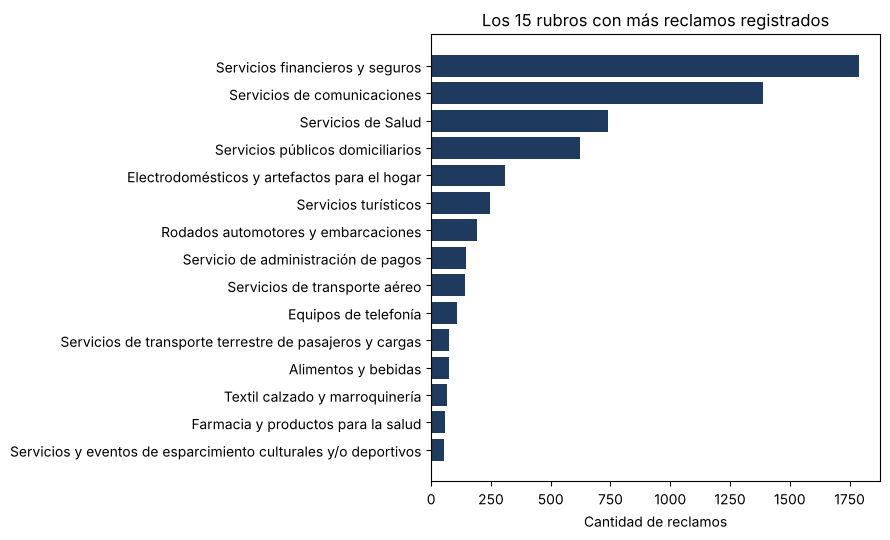

In [9]:
# Gráfico de barras horizontales de los 15 rubros más frecuentes (se invierte el orden para que el mayor quede arriba).
top = vc.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index, top.values, color="#1F3A5F")
ax.set_xlabel("Cantidad de reclamos")
ax.set_title("Los 15 rubros con más reclamos registrados")
plt.tight_layout()
plt.savefig(FIG / "01_rubros_top15.png", dpi=150)
plt.show()

**Variable objetivo:** `rubro` (en su versión agrupada, `rubro_agrupado`, definida en la sección 6). Indica el
rubro del bien o servicio reclamado. Sus valores posibles se listan en la sección 6.

Las clases están **muy desbalanceadas**: unos pocos rubros concentran la mayoría de los reclamos y muchos
tienen muy pocos casos. Con tan pocos ejemplos, un modelo no puede aprender a reconocer esos rubros, por lo que
conviene agruparlos (sección 7).

## 6. Partición entrenamiento / prueba

Se separa el 25 % de los reclamos para evaluar. La partición es **aleatoria y estratificada** por rubro (cada
conjunto conserva la proporción de cada rubro) y usa una semilla fija. Se hace **antes** de definir las clases y de
ajustar cualquier transformación, para que el conjunto de prueba no influya en ninguna decisión de diseño.

**Qué evalúa y qué no evalúa esta partición.** Una partición aleatoria sirve para evaluar el modelo con reclamos de
una distribución parecida a la de la muestra histórica. **No comprueba** que el modelo generalice a reclamos de
períodos posteriores: un modelo puede aplicarse a reclamos futuros aunque no incluya el tiempo entre sus
predictoras. Por eso, en el notebook de modelado se agrega una **evaluación temporal complementaria** (entrenar con
2021 y evaluar con 2022). Esa evaluación tiene su propia limitación: la fecha disponible es la de *tratamiento* del
reclamo, no necesariamente la de ingreso.

In [10]:
# Partición aleatoria estratificada por rubro. Los rubros con menos de 4 casos se juntan en '_raro' solo para
# poder estratificar (no define las clases del modelo). La semilla fija hace la partición reproducible.
tr, te = particion_entrenamiento_prueba(df, test_size=0.25, semilla=SEMILLA)
print("Reclamos: entrenamiento =", len(tr), "| prueba =", len(te))
print(f"Proporción del rubro más frecuente: entrenamiento {tr['rubro'].value_counts(normalize=True).iloc[0]:.1%}"
      f" | prueba {te['rubro'].value_counts(normalize=True).iloc[0]:.1%}")

Reclamos: entrenamiento = 4842 | prueba = 1615
Proporción del rubro más frecuente: entrenamiento 27.7% | prueba 27.7%


### Repeticiones de filas completas entre entrenamiento y prueba

En la sección 4 se informó que hay 173 filas idénticas a otra y que no se eliminan, porque podrían ser reclamos
distintos con el mismo perfil. Pero si una fila idéntica queda una en entrenamiento y otra en prueba, el modelo
podría «reconocerla» y el resultado se vería algo mejor de lo real. Se mide cuántas hay.

In [11]:
# clave_fila une las 8 columnas originales de cada reclamo en un texto: dos filas con la misma clave son idénticas.
clave_tr = clave_fila(tr)
clave_te = clave_fila(te)
claves_tr = set(clave_tr)

# Reclamos de prueba que tienen una fila completa idéntica en entrenamiento.
n_te_repetidas = int(clave_te.isin(claves_tr).sum())
# Grupos de filas idénticas que quedaron repartidos entre ambos conjuntos.
grupos_partidos = len(set(clave_te) & claves_tr)
print("Reclamos de prueba con una fila idéntica en entrenamiento:", n_te_repetidas,
      f"({n_te_repetidas / len(te):.1%} de la prueba)")
print("Grupos de filas idénticas repartidos entre entrenamiento y prueba:", grupos_partidos)

Reclamos de prueba con una fila idéntica en entrenamiento: 64 (4.0% de la prueba)
Grupos de filas idénticas repartidos entre entrenamiento y prueba: 61


Esto **no identifica personas**: dos reclamos con el mismo perfil no son necesariamente de la misma persona. Se
informa como limitación y, como análisis de sensibilidad, en el notebook de modelado se repite la evaluación
manteniendo juntas las filas idénticas al separar.

## 7. Definición de las clases con el entrenamiento

**Qué se decide.** Cuáles rubros se conservan como clase propia y cuáles se agrupan en `Otros`. La lista se
calcula **solo con el conjunto de entrenamiento** y luego se mantiene fija al evaluar: un rubro de prueba que no está
en la lista pasa a `Otros`. Así la prueba no interviene en cómo se definen las clases.

**Criterio:** se conserva todo rubro que represente al menos el **1,5 %** de los reclamos de entrenamiento (unos
73 reclamos). Es una regla práctica de tamaño mínimo de muestra, no una fuente oficial: con validación cruzada de
5 particiones, una clase de ese tamaño deja unos 15 casos para validar en cada una.

**Agrupar cambia el problema.** Con `Otros` ya no se clasifica entre todos los rubros, sino entre los más
frecuentes y «cualquier otro». Por eso, si se prueban otros umbrales, **no se pueden comparar las métricas como si
fueran el mismo problema**: una métrica más alta puede deberse a que la tarea se simplificó y no a que el modelo
mejoró. Cada variante se debe comparar con su propio modelo de referencia.

In [12]:
# Definición de las clases SOLO con el entrenamiento (definir_clases) y aplicación igual a entrenamiento y prueba.
PROPORCION_MINIMA = 0.015
clases_propias = definir_clases(tr["rubro"], proporcion_minima=PROPORCION_MINIMA)
tr["rubro_agrupado"] = aplicar_clases(tr["rubro"], clases_propias)
te["rubro_agrupado"] = aplicar_clases(te["rubro"], clases_propias)

conteo = pd.DataFrame({
    "entrenamiento": tr["rubro_agrupado"].value_counts(),
    "prueba": te["rubro_agrupado"].value_counts(),
})
print("Clases propias definidas con el entrenamiento:", len(clases_propias), "+ 'Otros' =", conteo.shape[0], "clases")
print(conteo)
print("Mínimo en entrenamiento:", conteo["entrenamiento"].min(), "| mínimo en prueba:", conteo["prueba"].min())

Clases propias definidas con el entrenamiento: 10 + 'Otros' = 11 clases
                                              entrenamiento  prueba
rubro_agrupado                                                     
Servicios financieros y seguros                        1341     447
Servicios de comunicaciones                            1042     348
Otros                                                   581     194
Servicios de Salud                                      555     185
Servicios públicos domiciliarios                        466     155
Electrodomésticos y artefactos para el hogar            231      77
Servicios turísticos                                    184      61
Rodados automotores y embarcaciones                     144      48
Servicio de administración de pagos                     110      37
Servicios de transporte aéreo                           106      35
Equipos de telefonía                                     82      28
Mínimo en entrenamiento: 82 | mínimo en prue

In [13]:
# Qué hay dentro de 'Otros' (en entrenamiento) y cuántos rubros de prueba no aparecen en entrenamiento.
en_otros_tr = tr.loc[tr["rubro_agrupado"] == "Otros", "rubro"].value_counts()
print(f"'Otros' en entrenamiento reúne {len(en_otros_tr)} rubros y {en_otros_tr.sum()} reclamos ({en_otros_tr.sum() / len(tr):.1%}).")
nuevos_en_prueba = set(te["rubro"]) - set(tr["rubro"])
print("Rubros que aparecen solo en prueba (pasan a 'Otros'):", len(nuevos_en_prueba))

'Otros' en entrenamiento reúne 36 rubros y 581 reclamos (12.0%).
Rubros que aparecen solo en prueba (pasan a 'Otros'): 1


In [14]:
# Comparación descriptiva de otros umbrales, calculados también con el entrenamiento: cuántas clases quedan y
# cuánto pesa 'Otros'. No son comparables entre sí como métricas: cada umbral define un problema distinto.
filas = []
for prop in [0.01, 0.015, 0.02]:
    claves = definir_clases(tr["rubro"], proporcion_minima=prop)
    otros = int((~tr["rubro"].isin(claves)).sum())
    filas.append({
        "proporción mínima": f"{prop:.1%}",
        "casos mínimos (entrenamiento)": round(prop * len(tr)),
        "clases propias": len(claves),
        "% de entrenamiento en 'Otros'": round(100 * otros / len(tr), 1),
    })
pd.DataFrame(filas)

,proporción mínima,casos mínimos (entrenamiento),clases propias,% de entrenamiento en 'Otros'
0,1.0%,48,13,8.7
1,1.5%,73,10,12.0
2,2.0%,97,9,13.7


**Qué se pierde al agrupar:** `Otros` es una clase heterogénea (reúne rubros muy distintos entre sí) y, por lo
tanto, un buen o mal resultado en esa clase no se puede interpretar como un rubro concreto. En el notebook de
modelado se repite la evaluación con las otras proporciones de la tabla, comparando cada una con su propio modelo
de referencia.

## 8. Variables sociodemográficas y territoriales

Exploración descriptiva del conjunto completo (no se usa para tomar decisiones sobre variables; las decisiones por
capacidad predictiva se evalúan dentro del entrenamiento).

In [15]:
# Distribución de las variables que se usarán para predecir: vulnerabilidad y género.
print(df["vulnerabilidad"].value_counts().to_frame("casos").assign(porcentaje=lambda t: (100 * t["casos"] / len(df)).round(1)))
print()
print(df["genero"].value_counts().to_frame("casos"))

                     casos  porcentaje
vulnerabilidad                        
Adulto/a mayor        3410        52.8
Socio-económica       1238        19.2
Discapacidad           647        10.0
Salud                  567         8.8
NNyA                   291         4.5
Turista                151         2.3
Barrios populares       56         0.9
LGTB+                   40         0.6
Violencia de género     27         0.4
Ruralidad               13         0.2
Migrante                10         0.2
Pueblos originarios      5         0.1
Ex-combatiente           2         0.0

            casos
genero           
Femenino     3910
Masculino    2544
No Binario      3


In [16]:
# Concentración territorial: si casi todo está en pocas provincias, las demás tienen pocos casos.
prov = df["provincia_consumidor"].value_counts()
print("Provincias:", len(prov))
print(f"CABA + Buenos Aires: {(prov.get('Ciudad Autónoma de Buenos Aires', 0) + prov.get('Buenos Aires', 0)) / len(df):.1%} de los registros")
prov.head(10)

Provincias: 24
CABA + Buenos Aires: 75.6% de los registros


provincia_consumidor
Ciudad Autónoma de Buenos Aires    3496
Buenos Aires                       1386
Córdoba                             400
Santa Fe                            173
Tucumán                             144
Río Negro                           108
Chubut                               79
San Luis                             73
Neuquén                              67
San Juan                             66
Name: count, dtype: int64

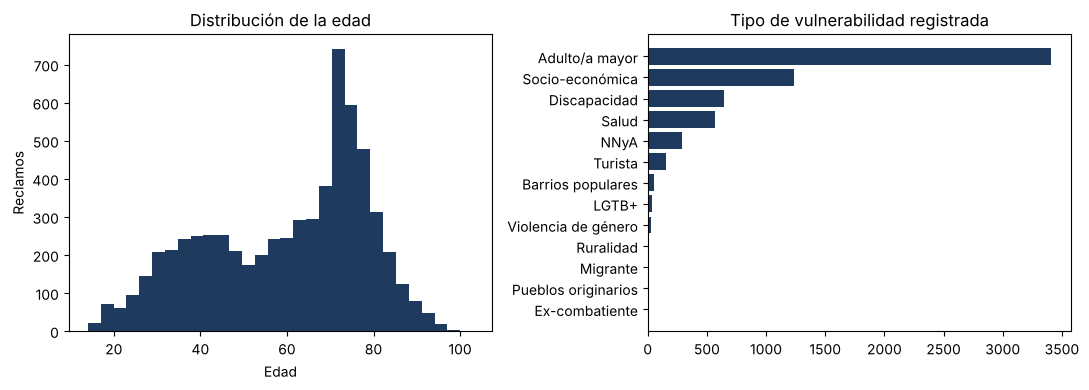

In [17]:
# Histograma de edad (forma de la distribución) y barras de vulnerabilidad (categorías dominantes).
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(df["edad"], bins=30, color="#1F3A5F")
axs[0].set_title("Distribución de la edad")
axs[0].set_xlabel("Edad")
axs[0].set_ylabel("Reclamos")
v = df["vulnerabilidad"].value_counts()[::-1]
axs[1].barh(v.index, v.values, color="#1F3A5F")
axs[1].set_title("Tipo de vulnerabilidad registrada")
plt.tight_layout()
plt.savefig(FIG / "02_edad_vulnerabilidad.png", dpi=150)
plt.show()

In [18]:
# Se cruza edad con vulnerabilidad para comprobar si los datos son coherentes entre sí
# (por ejemplo, que 'NNyA' tenga menores de edad) y entender qué representa la columna edad.
print("Edad por tipo de vulnerabilidad (mínimo, mediana, máximo):")
print(df.groupby("vulnerabilidad")["edad"].agg(["count", "min", "median", "max"]).sort_values("count", ascending=False))
print()
print("Registros con edad < 18:", int((df["edad"] < 18).sum()))
print("Vulnerabilidad 'NNyA' con edad >= 18:", int(((df["vulnerabilidad"] == "NNyA") & (df["edad"] >= 18)).sum()))
print("Vulnerabilidad 'Adulto/a mayor' con edad < 60:", int(((df["vulnerabilidad"] == "Adulto/a mayor") & (df["edad"] < 60)).sum()))

Edad por tipo de vulnerabilidad (mínimo, mediana, máximo):
                     count  min  median  max
vulnerabilidad                              
Adulto/a mayor        3410   16    73.0  103
Socio-económica       1238   16    46.0   95
Discapacidad           647   15    51.0   90
Salud                  567   18    42.0   97
NNyA                   291   14    37.0   78
Turista                151   19    48.0   88
Barrios populares       56   18    46.0   94
LGTB+                   40   21    30.0   61
Violencia de género     27   17    42.0   64
Ruralidad               13   29    53.0   66
Migrante                10   35    44.0   77
Pueblos originarios      5   32    48.0   64
Ex-combatiente           2   61    68.5   76

Registros con edad < 18: 50
Vulnerabilidad 'NNyA' con edad >= 18: 252
Vulnerabilidad 'Adulto/a mayor' con edad < 60: 412


**Observación y pregunta abierta.** Muchos registros de vulnerabilidad `NNyA` tienen edad de 18 años o más, y
algunos `Adulto/a mayor` tienen menos de 60. Una **hipótesis** es que `edad` corresponda a la persona que reclama
y no a la persona afectada, pero el diccionario de la ficha no describe las columnas y no se puede confirmar;
queda como pregunta para la fuente. Mientras tanto no se corrige ni se descarta ningún registro. Además, `edad` y
`vulnerabilidad` están parcialmente relacionadas (por ejemplo, `Adulto/a mayor`), por lo que pueden ser
redundantes entre sí.

## 9. Asociaciones dentro de los reclamos observados (conjunto de entrenamiento)

Lo que se puede estudiar es **qué rubros aparecen con más frecuencia entre los reclamos registrados de cada
grupo**. Es una asociación dentro de los reclamos observados: **no** mide qué grupos están más expuestos al
problema, porque no hay información de quienes no reclamaron ni de cuántas personas de cada grupo consumen cada
servicio.

Esta sección usa **solo el conjunto de entrenamiento** y es **descriptiva**: no se usa para excluir variables. Una
asociación individual baja no demuestra que una variable carezca de utilidad combinada con otras.

In [19]:
# Tabla cruzada con porcentajes por fila (solo entrenamiento): dentro de cada tipo de vulnerabilidad,
# cómo se reparten las clases de rubro.
tabla = pd.crosstab(tr["vulnerabilidad"], tr["rubro_agrupado"], normalize="index") * 100
orden = tr["vulnerabilidad"].value_counts().index  # ordenado de más a menos casos
tabla = tabla.loc[orden].round(1)
tabla

rubro_agrupado,Electrodomésticos y artefactos para el hogar,Equipos de telefonía,Otros,Rodados automotores y embarcaciones,Servicio de administración de pagos,Servicios de Salud,Servicios de comunicaciones,Servicios de transporte aéreo,Servicios financieros y seguros,Servicios públicos domiciliarios,Servicios turísticos
vulnerabilidad,,,,,,,,,,,
Adulto/a mayor,5.7,1.8,8.8,2.0,1.7,4.0,30.9,1.8,32.1,8.6,2.8
Socio-económica,4.2,1.6,15.5,4.7,3.5,1.5,11.4,0.4,40.7,14.7,1.7
Discapacidad,5.1,1.7,18.0,7.0,3.0,14.6,19.5,2.1,17.8,9.7,1.7
Salud,1.0,0.0,6.4,0.0,1.2,79.5,3.1,2.4,2.4,3.6,0.5
NNyA,4.2,3.8,24.5,1.7,2.1,13.1,6.8,1.7,9.7,18.1,14.3
Turista,0.0,0.0,16.3,1.0,0.0,0.0,1.0,29.8,4.8,0.0,47.1
Barrios populares,9.1,4.5,18.2,2.3,4.5,2.3,18.2,0.0,29.5,11.4,0.0
LGTB+,6.1,3.0,12.1,9.1,18.2,12.1,24.2,3.0,12.1,0.0,0.0
Violencia de género,4.8,0.0,52.4,0.0,4.8,4.8,9.5,4.8,9.5,0.0,9.5


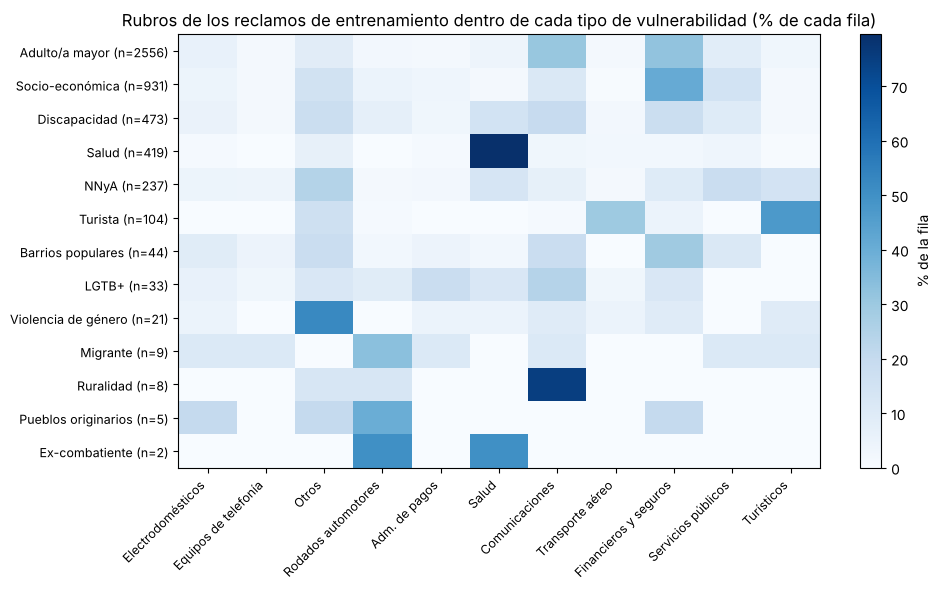

In [20]:
# Mapa de calor de la tabla anterior. Se acortan los nombres de rubros para que las etiquetas se lean bien
# y se muestra la cantidad de casos (n) de cada fila, porque las filas chicas son poco confiables.
cortos = {
    "Electrodomésticos y artefactos para el hogar": "Electrodomésticos",
    "Equipos de telefonía": "Equipos de telefonía",
    "Rodados automotores y embarcaciones": "Rodados automotores",
    "Servicio de administración de pagos": "Adm. de pagos",
    "Servicios de Salud": "Salud",
    "Servicios de comunicaciones": "Comunicaciones",
    "Servicios de transporte aéreo": "Transporte aéreo",
    "Servicios financieros y seguros": "Financieros y seguros",
    "Servicios públicos domiciliarios": "Servicios públicos",
    "Servicios turísticos": "Turísticos",
}
n_vul = tr["vulnerabilidad"].value_counts()
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(tabla.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(tabla.shape[1]))
ax.set_xticklabels([cortos.get(c, c) for c in tabla.columns], rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(tabla.shape[0]))
ax.set_yticklabels([f"{v} (n={n_vul[v]})" for v in tabla.index], fontsize=9)
ax.set_title("Rubros de los reclamos de entrenamiento dentro de cada tipo de vulnerabilidad (% de cada fila)")
fig.colorbar(im, ax=ax, label="% de la fila")
plt.tight_layout()
plt.savefig(FIG / "03_vulnerabilidad_por_rubro.png", dpi=150)
plt.show()

In [21]:
# Para los 5 tipos de vulnerabilidad con más casos: qué clase de rubro predomina y qué porcentaje de la fila representa.
for vul in orden[:5]:
    fila = tabla.loc[vul]
    print(f"{vul} (n={n_vul[vul]}): predomina {fila.idxmax()} ({fila.max():.0f} %)")

Adulto/a mayor (n=2556): predomina Servicios financieros y seguros (32 %)
Socio-económica (n=931): predomina Servicios financieros y seguros (41 %)
Discapacidad (n=473): predomina Servicios de comunicaciones (20 %)
Salud (n=419): predomina Servicios de Salud (80 %)
NNyA (n=237): predomina Otros (24 %)


**Cómo leer el gráfico:** cada fila suma 100 % y muestra cómo se reparten los reclamos de ese tipo de
vulnerabilidad entre rubros. Las filas con pocos casos (por ejemplo, ex-combatientes o pueblos originarios) no son
interpretables: un solo reclamo mueve mucho el porcentaje.

**Hipótesis (no conclusiones):** que en ciertos tipos de vulnerabilidad predomine un rubro concreto podría deberse a
que la vulnerabilidad se registra a partir de la situación que originó el reclamo (por ejemplo, un problema de salud
o de un viaje), y no a un riesgo propio del grupo. Con estos datos no se puede confirmar, y esto tiene una
consecuencia para el modelado: si la vulnerabilidad se determina **después** de clasificar el reclamo, usarla como
predictora introduciría información que no existiría en el momento de la predicción (ver sección 12).

In [22]:
# Intensidad de la asociación de cada variable con el rubro (V de Cramér: 0 = ninguna, 1 = total), solo entrenamiento.
# Es descriptivo: NO se usa para excluir variables. Con muchas categorías y pocos casos el V puede verse algo inflado.
filas = []
for col in ["vulnerabilidad", "genero", "provincia_consumidor", "mes", "anio"]:
    filas.append({"variable": col, "V de Cramér con rubro_agrupado": round(cramer_v(tr[col], tr["rubro_agrupado"]), 3)})
pd.DataFrame(filas).sort_values("V de Cramér con rubro_agrupado", ascending=False)

,variable,V de Cramér con rubro_agrupado
0,vulnerabilidad,0.283
4,anio,0.106
2,provincia_consumidor,0.093
1,genero,0.088
3,mes,0.076


El V de Cramér mide la intensidad de la asociación entre dos variables categóricas (0 = ninguna; 1 = total). Se
interpreta solo como asociación descriptiva en estos reclamos; no es causal ni mide exposición. Que una asociación
individual sea baja **no** es motivo para excluir una variable: la utilidad de cada variable se evaluará dentro del
entrenamiento, con los modelos.

## 10. Variable temporal (`mes_anio_tratamiento`)

La fecha que trae el dataset es la de **tratamiento** del reclamo, no necesariamente la de ingreso. Si el uso
previsto es clasificar un reclamo **al momento de ingresarlo**, esa fecha todavía podría no existir. Esta es una
decisión **por disponibilidad**, no por capacidad predictiva.

Período: 2021-01 a 2022-12 | 24 meses
Reclamos por mes: mínimo 105 | máximo 426
Reclamos por año: {2021: 3086, 2022: 3371}


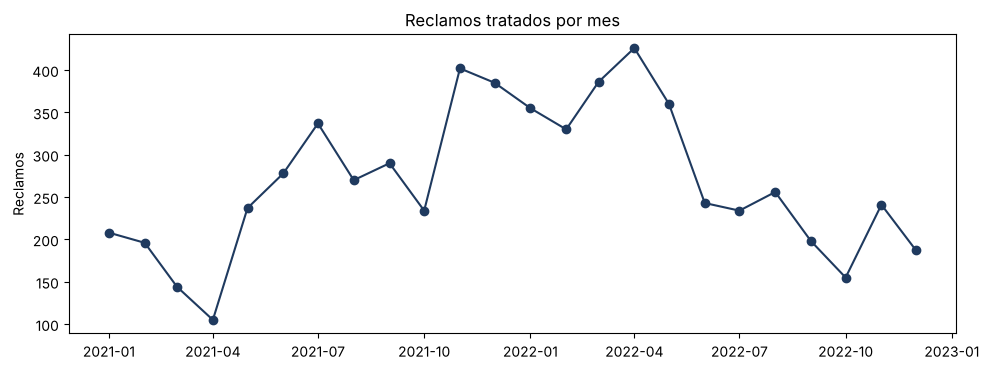

In [23]:
# Se convierte mes + año en una fecha real para poder graficar la evolución en el tiempo.
meses = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6, "jul": 7, "ago": 8, "sep": 9, "oct": 10, "nov": 11, "dic": 12}
df["periodo"] = pd.to_datetime(dict(year=df["anio"], month=df["mes"].map(meses), day=1))
por_mes = df.groupby("periodo").size()  # cantidad de reclamos tratados en cada mes
print("Período:", por_mes.index.min().strftime("%Y-%m"), "a", por_mes.index.max().strftime("%Y-%m"), "|", len(por_mes), "meses")
print("Reclamos por mes: mínimo", por_mes.min(), "| máximo", por_mes.max())
print("Reclamos por año:", df.groupby("anio").size().to_dict())
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(por_mes.index, por_mes.values, marker="o", color="#1F3A5F")
ax.set_title("Reclamos tratados por mes")
ax.set_ylabel("Reclamos")
plt.tight_layout()
plt.savefig(FIG / "04_reclamos_por_mes.png", dpi=150)
plt.show()

**Decisión:** `mes` y `anio` **no se usan como predictoras**, porque no se sabe si la fecha de tratamiento está
disponible al ingresar el reclamo. No se excluyen por tener baja asociación con el rubro. El año sí se usa para
**separar períodos** en la evaluación temporal complementaria del notebook de modelado (entrenar con 2021 y evaluar
con 2022).

## 11. El motivo del reclamo: ¿puede revelar el rubro? (conjunto de entrenamiento)

El motivo se podría seleccionar a partir de un rubro ya asignado, y en ese caso revelaría indirectamente la
respuesta. Como no se sabe cómo se registra, se mide cuánto del rubro se puede deducir del motivo. La exclusión se
decide por **disponibilidad y posible fuga de información**; la medición ilustra el riesgo.

In [24]:
# Tabla motivo x rubro (solo entrenamiento). La 'pureza' de un motivo es la fracción de sus reclamos que cae en su
# rubro más frecuente: 1 significa que ese motivo aparece siempre con un único rubro (lo revela por completo).
ct = pd.crosstab(tr["motivo"], tr["rubro"])
pureza = ct.max(axis=1) / ct.sum(axis=1)
peso = ct.sum(axis=1) / ct.values.sum()   # peso de cada motivo en el total de reclamos
print("Motivos distintos:", len(ct))
print("Pureza ponderada (fracción de reclamos cuyo rubro es el más frecuente de su motivo):", round(float((pureza * peso).sum()), 3))
exclusivos = pureza[pureza == 1].index
print("Motivos que aparecen siempre con un único rubro:", len(exclusivos), "de", len(ct), "| cubren", f"{peso[exclusivos].sum():.1%} de los reclamos")
print()
print("Ejemplos de motivos que determinan el rubro:")
print(ct.loc[exclusivos].idxmax(axis=1).head(5).to_string())

Motivos distintos: 47
Pureza ponderada (fracción de reclamos cuyo rubro es el más frecuente de su motivo): 0.498
Motivos que aparecen siempre con un único rubro: 24 de 47 | cubren 16.9% de los reclamos

Ejemplos de motivos que determinan el rubro:
motivo
Aumento de cuota no autorizado/no notificado con anticipación debida                                               Servicios de Salud
Baja de efectores y/o profesionales de la cartilla de prestaciones médicas                                         Servicios de Salud
Cancelación o supresión de vuelos                                                                       Servicios de transporte aéreo
Cumplimiento parcial o defectuoso de la prestación del servicio educativo                                      Servicios de Enseñanza
Cumplimiento parcial o defectuoso de la prestación médica o de cobertura de la medicación prescripta               Servicios de Salud


In [25]:
# Contraste: motivos genéricos que se reparten entre muchos rubros (cuántos rubros distintos tiene cada uno).
rubros_por_motivo = (ct > 0).sum(axis=1).sort_values(ascending=False)
print("Motivos que aparecen en más rubros distintos:")
print(rubros_por_motivo.head(5).to_string())

Motivos que aparecen en más rubros distintos:
motivo
Prácticas Abusivas                                                                  25
Incumplimiento de Oferta Promociones y/o Bonificaciones. Art. 7 de la Ley 24.240    24
Cumplimiento parcial o defectuoso de la prestación del servicio                     22
Problemas de fraude o estafa                                                        22
Precios                                                                             21


**Resultado:** una parte de los motivos aparece siempre con un único rubro, por lo que el motivo puede revelar el
rubro; otros son genéricos y aparecen en muchos rubros. Por eso el análisis principal **no usa** el motivo. Si se
incorpora como escenario complementario, se presenta aclarando esta limitación y como respuesta a una pregunta
distinta (clasificar el rubro a partir del motivo y el perfil), no como una mejora del modelo principal.

## 12. Variables disponibles y escenarios

La pregunta que decide qué variables se pueden usar es: **en el momento de usar el modelo, ¿se tendrá disponible
esa variable?** Uso previsto (supuesto): clasificar un reclamo cuando se ingresa, antes de conocer su rubro.

| Variable | ¿Disponible al ingreso? | Tratamiento |
|---|---|---|
| `edad`, `genero`, `provincia_consumidor` | Se supone que sí (datos de la persona) | Predictoras en todos los escenarios |
| `vulnerabilidad` | **No confirmado.** La ficha indica que el organismo la *detecta*; no dice cuándo ni cómo. Categorías como «Salud» o «Turista» podrían asignarse a partir de la situación que originó el reclamo | **Escenario A:** se usa, condicionado a ese supuesto. **Escenario B:** no se usa |
| `motivo` | Puede no estar disponible o revelar el rubro | No se usa |
| `mes_anio_tratamiento` | Es fecha de tratamiento, no de ingreso | No se usa como predictora |
| `provincia_id` | Duplica a `provincia_consumidor` (equivalencia uno a uno) | No se usa |

Que `vulnerabilidad` esté asociada con el rubro **no demuestra** que haya fuga de información; lo que falta es
confirmar cuándo se registra. Mientras no se confirme, se presentan **los dos escenarios** y se comparan.

## 13. Preprocesamiento para el modelado

**Predictoras:** categóricas `vulnerabilidad` (solo escenario A), `genero` y `provincia_consumidor`; numérica `edad`.

**Transformaciones** (definidas en `consumidores_hipervulnerables/features.py`):
- **Codificación one-hot** de las categóricas: los modelos necesitan números. Las categorías con menos de 5 casos se
  agrupan en una categoría «infrecuente».
- **Escalado (estandarización) de `edad`**: se resta la media y se divide por el desvío para llevarla a una escala
  comparable con las columnas 0/1. Importa para modelos basados en distancias, como K-NN. **El escalado no sirve para
  eliminar redundancia ni correlación entre variables**; solo pone las variables en una escala común.
- Las transformaciones se **ajustan solo con el conjunto de entrenamiento** y luego se aplican al de prueba.

**Cómo se conserva el procedimiento.** Se guarda el **preprocesador ajustado** (con `joblib`) para transformar
reclamos nuevos de la misma manera. Además, en el notebook de modelado el preprocesador va **dentro de un
`Pipeline`**, de modo que en cada partición de la validación cruzada se vuelve a ajustar solo con los datos de
entrenamiento de esa partición. Usar directamente la matriz ya transformada con todo el entrenamiento haría que las
categorías y el escalado «conocieran» los datos de validación. Los CSV de `data/processed/` sirven para inspeccionar
el resultado, pero **no se usan para validar**.

In [26]:
# ESCENARIOS (definido en features.py): A incluye vulnerabilidad (condicionado al supuesto de disponibilidad); B no.

MODELOS.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)
resumen = []
for nombre, cols in ESCENARIOS.items():
    # construir_preprocesador devuelve el ColumnTransformer sin ajustar. fit_transform aprende las categorías y la
    # media/desvío con el ENTRENAMIENTO; transform los aplica a la prueba sin volver a ajustar.
    prep = construir_preprocesador(cols["cat"], cols["num"])
    X_tr = prep.fit_transform(tr[cols["cat"] + cols["num"]])
    X_te = prep.transform(te[cols["cat"] + cols["num"]])
    nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    X_tr = pd.DataFrame(X_tr, columns=nombres, index=tr.index)
    X_te = pd.DataFrame(X_te, columns=nombres, index=te.index)

    # Se guarda el preprocesador ajustado (para transformar reclamos nuevos igual) y las matrices para inspección.
    joblib.dump(prep, MODELOS / f"preprocesador_escenario_{nombre}.joblib")
    X_tr.to_csv(PROCESSED / f"X_train_{nombre}.csv", index=False)
    X_te.to_csv(PROCESSED / f"X_test_{nombre}.csv", index=False)

    # Verificaciones: edad escalada con media ~0 y desvío ~1 en entrenamiento; un 1 por variable categórica en cada fila.
    cols_cat = [c for c in nombres if c != "edad"]
    resumen.append({
        "escenario": nombre,
        "columnas": len(nombres),
        "edad media (entrenamiento)": round(X_tr["edad"].mean(), 3),
        "edad desvío (entrenamiento)": round(X_tr["edad"].std(ddof=0), 3),
        "unos por fila": sorted(set(X_tr[cols_cat].sum(axis=1).astype(int))),
        "unos esperados": len(cols["cat"]),
        "faltantes": int(X_tr.isna().sum().sum() + X_te.isna().sum().sum()),
    })
tr["rubro_agrupado"].to_csv(PROCESSED / "y_train.csv", index=False, header=True)
te["rubro_agrupado"].to_csv(PROCESSED / "y_test.csv", index=False, header=True)
pd.DataFrame(resumen)

,escenario,columnas,edad media (entrenamiento),edad desvío (entrenamiento),unos por fila,unos esperados,faltantes
0,A,41,0.0,1.0,[3],3,0
1,B,28,0.0,1.0,[2],2,0


In [27]:
# Comprobación de que el preprocesador guardado se puede volver a cargar y transforma igual (reclamos nuevos).
prep_A = joblib.load(MODELOS / "preprocesador_escenario_A.joblib")
ejemplo = pd.DataFrame([{"vulnerabilidad": "Adulto/a mayor", "genero": "Femenino", "provincia_consumidor": "Córdoba", "edad": 70}])
print("Columnas generadas para un reclamo nuevo:", prep_A.transform(ejemplo).shape)
print("La transformación coincide con la de entrenamiento:", bool(np.allclose(
    prep_A.transform(tr[["vulnerabilidad", "genero", "provincia_consumidor", "edad"]].head(5)),
    pd.read_csv(PROCESSED / "X_train_A.csv").head(5).values)))

Columnas generadas para un reclamo nuevo: (1, 41)
La transformación coincide con la de entrenamiento: True


## 14. Guardado del dataset normalizado

In [28]:
# Se guarda el dataset limpio (sin tocar el original) en data/interim, indicando a qué conjunto pertenece cada reclamo.
INTERIM.parent.mkdir(parents=True, exist_ok=True)
df["particion"] = "entrenamiento"
df.loc[te.index, "particion"] = "prueba"
df["rubro_agrupado"] = pd.concat([tr["rubro_agrupado"], te["rubro_agrupado"]])
columnas = ["rubro", "rubro_agrupado", "particion", "motivo", "vulnerabilidad", "mes_anio_tratamiento", "mes", "anio",
            "edad", "genero", "provincia_consumidor", "provincia_id"]
df[columnas].to_csv(INTERIM, index=False, encoding="utf-8")
print("Guardado en data/interim/", INTERIM.name, "-", len(df), "filas |", df["particion"].value_counts().to_dict())

Guardado en data/interim/ consumidores_normalizado.csv - 6457 filas | {'entrenamiento': 4842, 'prueba': 1615}


## 15. Resumen de decisiones para el modelado

1. **Afirmaciones:** los resultados se interpretan como asociaciones dentro de los reclamos registrados entre
   enero de 2021 y diciembre de 2022; no se habla de exposición ni de grupos «más afectados». Las explicaciones
   posibles se presentan como hipótesis.
2. **Partición:** aleatoria estratificada 75/25 (semilla 42). Evalúa reclamos de una distribución parecida a la
   histórica; la generalización a períodos posteriores se evalúa aparte (2021 → 2022).
3. **Clases:** la lista de rubros que se conservan (≥ 1,5 % del entrenamiento) se define **solo con el entrenamiento**
   y se mantiene fija al evaluar. Cada umbral es un problema distinto.
4. **Variables:** edad, género y provincia en todos los escenarios; `vulnerabilidad` solo en el escenario A,
   condicionado a un supuesto de disponibilidad que no está confirmado. Sin motivo, sin fecha de tratamiento y sin
   `provincia_id`. Las exclusiones son por **disponibilidad o redundancia exacta**, no por asociación baja.
5. **Preprocesamiento:** preprocesador ajustado y guardado en `models/`; dentro de un `Pipeline` en la validación
   cruzada.
6. **Repeticiones:** no se eliminan; se midieron las que cruzan entrenamiento y prueba y se hará un análisis de
   sensibilidad manteniéndolas juntas.
7. **Modelo de referencia:** clase mayoritaria elegida con el entrenamiento y evaluada en la prueba con las mismas
   métricas que los demás modelos.
8. **Desbalance:** regresión logística y árbol de decisión admiten `class_weight`; K-NN no. En K-NN, `weights`
   solo pondera el voto de los vecinos y **no** equivale a ponderar clases.
